# RQ2 presentation figures: effect of targeted copy-paste augmentation on the focus species

Four slide figures (16:9) for the RQ2 section of the talk:

1. **All six models improved**: focus-species mean AP50, baseline → augmented, with change, 95% CI and Holm-adjusted p
2. **Per-species gains**: Convict Tang, Forcepsfish, Orangespine Unicornfish (mean over the six models)
3. **Consistency**: change for each species in each of the 12 model–seed runs
4. **Error breakdown**: what happened to each focus-species fish (correct / wrong species / poorly localised / missed)

**Data source.** All values are copied from the existing analysis of the pooled out-of-fold test predictions
(120 runs; seeds averaged unless stated), so this notebook needs no data files and runs anywhere.
AP50: detection scored with box IoU, segmentation with mask IoU. CIs are 95% paired block-bootstrap intervals
(2,000 resamples of the 49 temporal blocks). Holm adjustment is across the 6 configurations (figure 1)
and across the 3 species (figure 2). The error breakdown (figure 4) uses confidence ≥ 0.25 and box IoU ≥ 0.5 for all models,
pooled over 6 models × 2 seeds, so its "correct" share is recall, not AP50.

Set `THEME` to `'light'` or `'dark'` to match your slides.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

THEME = 'light'          # 'light' or 'dark'
SAVE = True
DPI = 150

## Data

In [2]:
MODELS = ['detect_s', 'detect_m', 'detect_l', 'segment_s', 'segment_m', 'segment_l']
LABEL = {'detect_s': 'Detection S', 'detect_m': 'Detection M', 'detect_l': 'Detection L',
         'segment_s': 'Segmentation S', 'segment_m': 'Segmentation M', 'segment_l': 'Segmentation L'}

# Focus-species mean AP50 (mean of the 3 species), seeds averaged
FOCUS = {  # baseline, augmented, [change, CI low, CI high], Holm-adjusted p (across 6 configurations)
    'detect_s':  (0.267, 0.357, [0.090, 0.026, 0.150], 'p = 0.027'),
    'detect_m':  (0.335, 0.424, [0.089, 0.041, 0.144], 'p = 0.004'),
    'detect_l':  (0.373, 0.440, [0.068, 0.015, 0.138], 'p = 0.027'),
    'segment_s': (0.239, 0.355, [0.116, 0.049, 0.176], 'p < 0.006'),
    'segment_m': (0.308, 0.458, [0.149, 0.099, 0.217], 'p < 0.006'),
    'segment_l': (0.361, 0.444, [0.084, 0.020, 0.148], 'p = 0.027')}

SPECIES = ['Convict Tang', 'Forcepsfish', 'Orangespine Unicornfish']
N_INSTANCES = {'Convict Tang': 33, 'Forcepsfish': 93, 'Orangespine Unicornfish': 77}
# AP50 averaged over the 6 models: baseline, augmented, [change, CI low, CI high], Holm p (across 3 species)
SP = {'Convict Tang':            (0.414, 0.580, [0.166, 0.073, 0.267], 'p < 0.001'),
      'Forcepsfish':             (0.358, 0.460, [0.103, 0.031, 0.186], 'p = 0.006'),
      'Orangespine Unicornfish': (0.170, 0.199, [0.029, 0.001, 0.071], 'p = 0.047')}

# Change in AP50 (augmented - baseline) in each of the 12 model-seed runs
RUNS = ['detect_s_s0', 'detect_s_s1', 'detect_m_s0', 'detect_m_s1', 'detect_l_s0', 'detect_l_s1',
        'segment_s_s0', 'segment_s_s1', 'segment_m_s0', 'segment_m_s1', 'segment_l_s0', 'segment_l_s1']
PER_RUN = {
    'Convict Tang':            [0.204, 0.104, 0.165, 0.142, 0.044, 0.171, 0.210, 0.221, 0.175, 0.325, 0.104, 0.128],
    'Forcepsfish':             [0.061, 0.085, 0.115, -0.036, 0.121, 0.173, 0.079, 0.183, 0.171, 0.050, 0.091, 0.141],
    'Orangespine Unicornfish': [0.009, 0.078, 0.050, 0.095, -0.070, -0.032, 0.0003, 0.003, 0.083, 0.092, 0.139, -0.101]}
# note: Orangespine segment_s seed 0 is a very small positive change (+0.0003)

# Fate of each annotated focus-species fish (share of fish), conf >= 0.25, box IoU >= 0.5, pooled 6 models x 2 seeds
FATE_CATS = ['Correct', 'Wrong species', 'Poorly localised', 'Missed']
FATE = {
    'Forcepsfish':             {'Baseline': [0.2679, 0.2473, 0.0824, 0.4023], 'Augmented': [0.4032, 0.1720, 0.0565, 0.3683]},
    'Orangespine Unicornfish': {'Baseline': [0.1548, 0.1537, 0.0271, 0.6645], 'Augmented': [0.1959, 0.1418, 0.0184, 0.6439]},
    'Convict Tang':            {'Baseline': [0.3561, 0.1162, 0.0025, 0.5253], 'Augmented': [0.5884, 0.0758, 0.0025, 0.3333]}}
# key changes (augmented - baseline) with 95% CI
FATE_NOTES = {'Forcepsfish': 'Wrong species: −7.5 pp [−14.3, −2.1]',
              'Orangespine Unicornfish': 'No category changed significantly (missed: −2.1 pp [−10.5, +1.6])',
              'Convict Tang': 'Missed: −19.2 pp [−28.3, −14.3]'}

## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', axis='#898781',
                  blue='#2a78d6', orange='#eb6834', violet='#6250d6', base='#a3a29b'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', axis='#6d7a8e',
                  blue='#4a90e8', orange='#e2683a', violet='#9085e9', base='#7f8a9b'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 16, 'text.color': T['ink'],
                     'axes.labelcolor': T['ink2'], 'axes.edgecolor': T['axis'], 'xtick.color': T['ink2'],
                     'ytick.color': T['ink2'], 'axes.facecolor': T['bg'], 'figure.facecolor': T['bg'],
                     'savefig.facecolor': T['bg'], 'axes.titlesize': 20, 'axes.titleweight': 'bold',
                     'axes.titlecolor': T['ink'], 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.frameon': False, 'legend.fontsize': 15})
FS = (13.33, 7.5)

def clean(ax, grid='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if grid: ax.grid(axis=grid, color=T['grid'], lw=1); ax.set_axisbelow(True)
    ax.tick_params(length=0)

def save(fig, name):
    if SAVE:
        for ext in ('png', 'pdf'): fig.savefig(f'{name}_{THEME}.{ext}', dpi=DPI)
    plt.show()

## Figure 1: All six models improved
*"Increases in focus-species AP50 ranged from approximately 0.07 to 0.15 ... the medium segmentation model, 0.308 to 0.458.
Before augmentation, large detection achieved the highest ... after augmentation, medium segmentation."*

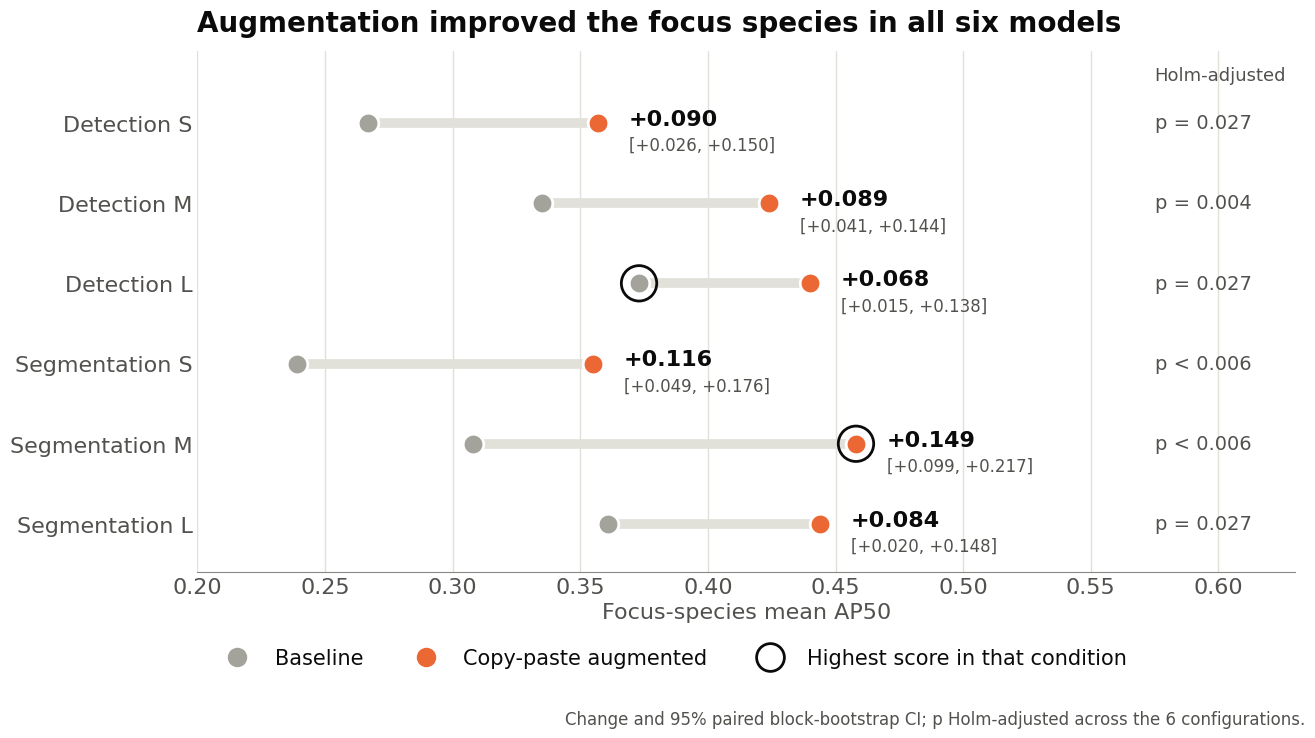

In [4]:
fig, ax = plt.subplots(figsize=FS)
order = MODELS[::-1]
for i, m in enumerate(order):
    b, a, (d, lo, hi), p = FOCUS[m]
    ax.plot([b, a], [i, i], color=T['grid'], lw=7, solid_capstyle='round', zorder=1)
    ax.scatter(b, i, s=220, color=T['base'], zorder=3, edgecolor=T['bg'], lw=2)
    ax.scatter(a, i, s=220, color=T['orange'], zorder=3, edgecolor=T['bg'], lw=2)
    ax.text(a + 0.012, i + 0.05, f'+{d:.3f}', va='center', fontsize=16, fontweight='bold', color=T['ink'])
    ax.text(a + 0.012, i - 0.28, f'[{lo:+.3f}, {hi:+.3f}]', va='center', fontsize=12, color=T['ink2'])
    ax.text(0.575, i, p, va='center', fontsize=14, color=T['ink2'])
ax.text(0.575, 5.6, 'Holm-adjusted', fontsize=13, color=T['ink2'], va='center')
# ring the best model in each condition
best_b = max(MODELS, key=lambda m: FOCUS[m][0]); best_a = max(MODELS, key=lambda m: FOCUS[m][1])
ax.scatter(FOCUS[best_b][0], order.index(best_b), s=650, facecolor='none', edgecolor=T['ink'], lw=2, zorder=4)
ax.scatter(FOCUS[best_a][1], order.index(best_a), s=650, facecolor='none', edgecolor=T['ink'], lw=2, zorder=4)
ax.set_yticks(range(6)); ax.set_yticklabels([LABEL[m] for m in order], fontsize=16)
ax.set_xlim(0.2, 0.63); ax.set_ylim(-0.6, 5.9); ax.set_xlabel('Focus-species mean AP50')
clean(ax, grid='x'); ax.spines['left'].set_visible(False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=13, color=T['base']),
                   Line2D([], [], marker='o', ls='', ms=13, color=T['orange']),
                   Line2D([], [], marker='o', ls='', ms=20, mfc='none', mec=T['ink'], mew=2)],
          labels=['Baseline', 'Copy-paste augmented', 'Highest score in that condition'], loc='lower left', ncol=3,
          bbox_to_anchor=(0, -0.22))
ax.set_title('Augmentation improved the focus species in all six models')
fig.text(0.99, 0.015, 'Change and 95% paired block-bootstrap CI; p Holm-adjusted across the 6 configurations.',
         fontsize=12, color=T['ink2'], ha='right')
fig.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, 'rq2_fig1_all_models')

## Figure 2: Gains differed between species
*"Convict Tang ... 0.414 to 0.580 ... Forcepsfish 0.358 to 0.460 ... Orangespine Unicornfish 0.170 to 0.199."*

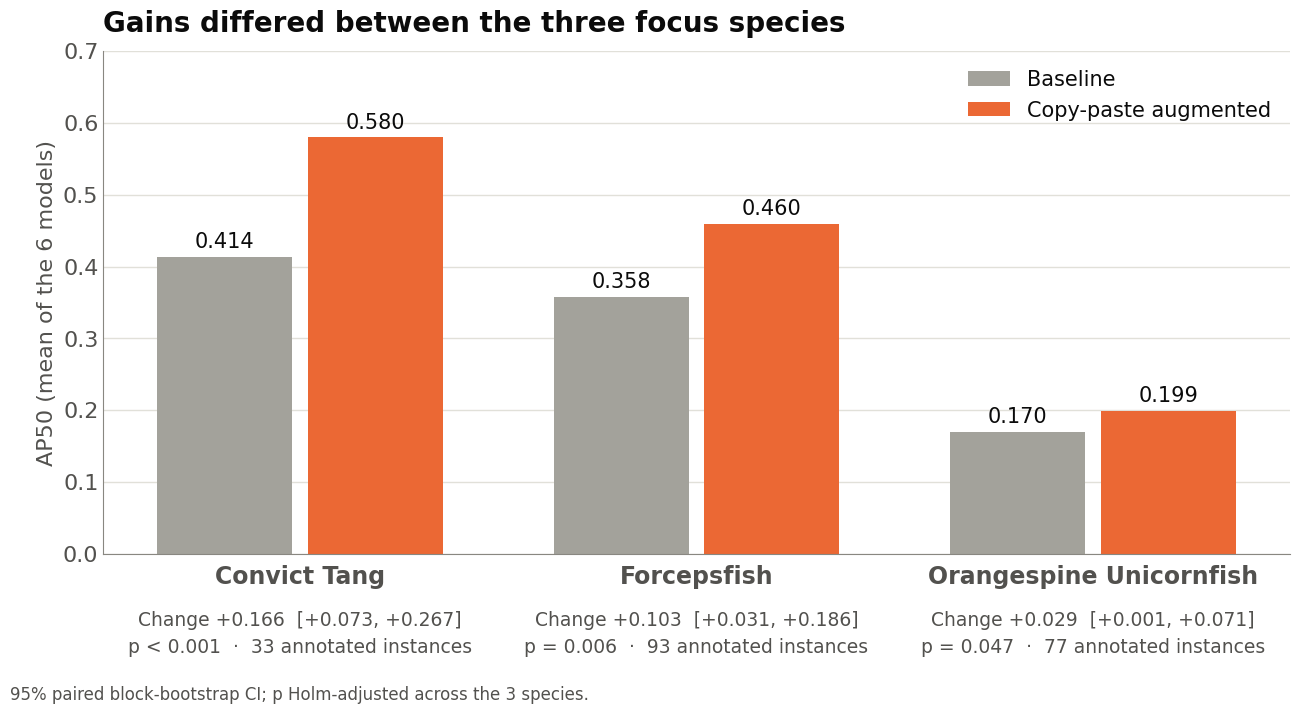

In [5]:
fig, ax = plt.subplots(figsize=FS)
w = 0.34
for j, s in enumerate(SPECIES):
    b, a, (d, lo, hi), p = SP[s]
    ax.bar(j - w / 2 - 0.02, b, w, color=T['base'], label='Baseline' if j == 0 else None)
    ax.bar(j + w / 2 + 0.02, a, w, color=T['orange'], label='Copy-paste augmented' if j == 0 else None)
    ax.text(j - w / 2 - 0.02, b + 0.012, f'{b:.3f}', ha='center', fontsize=15, color=T['ink'])
    ax.text(j + w / 2 + 0.02, a + 0.012, f'{a:.3f}', ha='center', fontsize=15, color=T['ink'])
    ax.text(j, -0.08, f'Change {d:+.3f}  [{lo:+.3f}, {hi:+.3f}]\n{p}  ·  {N_INSTANCES[s]} annotated instances',
            ha='center', va='top', fontsize=13.5, color=T['ink2'], linespacing=1.5)
ax.set_xticks(range(3)); ax.set_xticklabels(SPECIES, fontsize=17, fontweight='bold'); ax.tick_params(axis='x', pad=8)
ax.set_ylim(0, 0.7); ax.set_ylabel('AP50 (mean of the 6 models)'); clean(ax); ax.legend(loc='upper right')
ax.set_title('Gains differed between the three focus species')
fig.text(0.01, 0.015, '95% paired block-bootstrap CI; p Holm-adjusted across the 3 species.', fontsize=12, color=T['ink2'])
fig.subplots_adjust(left=0.08, right=0.97, top=0.88, bottom=0.21); save(fig, 'rq2_fig2_species')

## Figure 3: How consistent was the gain?
*"This improvement was observed across all 12 model and seed combinations."*

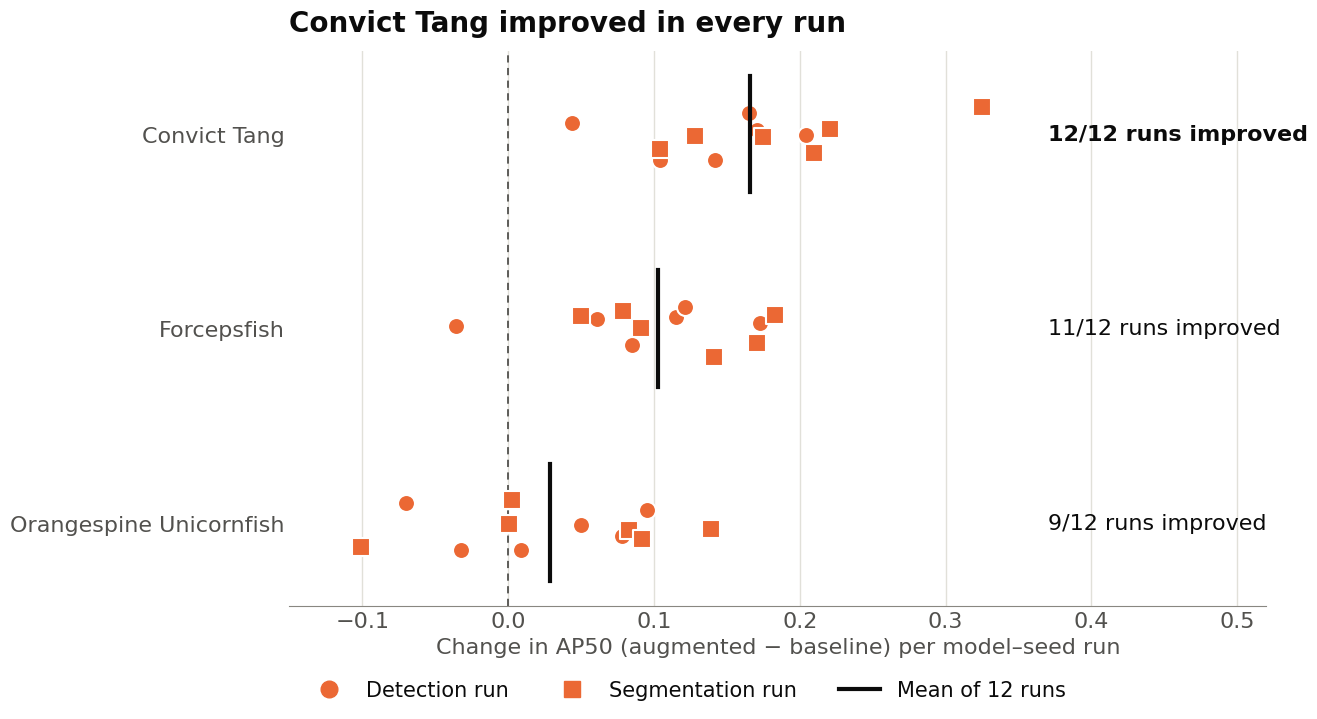

In [6]:
fig, ax = plt.subplots(figsize=FS)
rng = np.random.default_rng(1)
for j, s in enumerate(SPECIES):
    v = np.array(PER_RUN[s]); y = j + rng.uniform(-0.15, 0.15, len(v))
    det = np.array([r.startswith('detect') for r in RUNS])
    ax.scatter(v[det], y[det], s=150, marker='o', color=T['orange'], edgecolor=T['bg'], lw=1.5, zorder=3)
    ax.scatter(v[~det], y[~det], s=150, marker='s', color=T['orange'], edgecolor=T['bg'], lw=1.5, zorder=3)
    ax.plot([v.mean()] * 2, [j - 0.3, j + 0.3], color=T['ink'], lw=3, zorder=4)
    k = int((v > 0).sum())
    ax.text(0.37, j, f'{k}/12 runs improved', va='center', fontsize=16,
            fontweight='bold' if k == 12 else 'normal', color=T['ink'])
ax.axvline(0, color=T['ink2'], lw=1.3, ls=(0, (4, 3)))
ax.set_yticks(range(3)); ax.set_yticklabels(SPECIES, fontsize=16); ax.invert_yaxis()
ax.set_xlim(-0.15, 0.52); ax.set_xlabel('Change in AP50 (augmented − baseline) per model–seed run')
clean(ax, grid='x'); ax.spines['left'].set_visible(False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=12, color=T['orange']),
                   Line2D([], [], marker='s', ls='', ms=12, color=T['orange']),
                   Line2D([], [], color=T['ink'], lw=3)],
          labels=['Detection run', 'Segmentation run', 'Mean of 12 runs'], loc='upper left', ncol=3, bbox_to_anchor=(0, -0.1))
ax.set_title('Convict Tang improved in every run')
fig.tight_layout(); save(fig, 'rq2_fig3_consistency')

## Figure 4: What happened to each focus-species fish?
*"Augmentation reduced incorrect species classifications for Forcepsfish while the improvement for Convict Tang was primarily
associated with fewer missed detections. However, Orangespine Unicornfish remained difficult to recognise."*

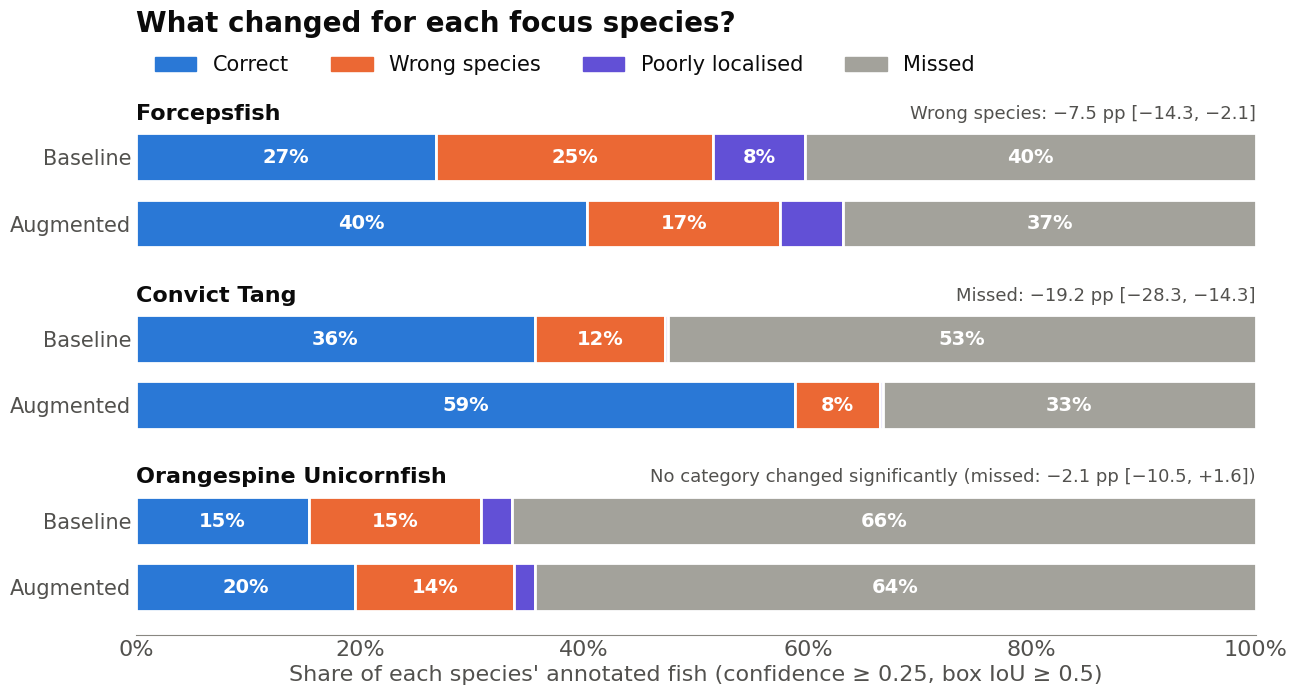

In [7]:
fig, ax = plt.subplots(figsize=FS)
cols = [T['blue'], T['orange'], T['violet'], T['base']]
order = ['Forcepsfish', 'Convict Tang', 'Orangespine Unicornfish']
y, ys, labs = 0, [], []
for s in order:
    for arm in ['Baseline', 'Augmented']:
        left = 0
        for v, c in zip(FATE[s][arm], cols):
            ax.barh(y, v, left=left, color=c, height=0.72, edgecolor=T['bg'], lw=2)
            if v >= 0.06:
                ax.text(left + v / 2, y, f'{v:.0%}', ha='center', va='center', fontsize=14, fontweight='bold',
                        color='white' if (c != T['base'] or THEME == 'light') else T['bg'])
            left += v
        ys.append(y); labs.append(arm); y += 1
    y += 0.75
ax.set_yticks(ys); ax.set_yticklabels(labs, fontsize=15); ax.invert_yaxis()
for j, s in enumerate(order):
    ax.text(0, ys[2 * j] - 0.66, s, ha='left', va='center', fontsize=16, fontweight='bold', color=T['ink'],
            transform=ax.get_yaxis_transform())
    ax.text(1, ys[2 * j] - 0.66, FATE_NOTES[s], ha='right', va='center', fontsize=13, color=T['ink2'],
            transform=ax.get_yaxis_transform())
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of each species' annotated fish (confidence ≥ 0.25, box IoU ≥ 0.5)")
clean(ax, grid=None); ax.spines['left'].set_visible(False)
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in cols], labels=FATE_CATS, ncol=4,
          loc='lower left', bbox_to_anchor=(0, 1.03))
ax.set_title('What changed for each focus species?', pad=56)
fig.subplots_adjust(left=0.13, right=0.97, top=0.82, bottom=0.12); save(fig, 'rq2_fig4_error_breakdown')

## Numbers for the script

In [8]:
d = [FOCUS[m][2][0] for m in MODELS]
print('Focus-species gains: %.3f to %.3f' % (min(d), max(d)))
print('Best baseline:', LABEL[max(MODELS, key=lambda m: FOCUS[m][0])], max(v[0] for v in FOCUS.values()))
print('Best augmented:', LABEL[max(MODELS, key=lambda m: FOCUS[m][1])], max(v[1] for v in FOCUS.values()))
for s in SPECIES:
    print(f'{s:25s} {SP[s][0]:.3f} -> {SP[s][1]:.3f}  ({sum(v > 0 for v in PER_RUN[s])}/12 runs improved)')

Focus-species gains: 0.068 to 0.149
Best baseline: Detection L 0.373
Best augmented: Segmentation M 0.458
Convict Tang              0.414 -> 0.580  (12/12 runs improved)
Forcepsfish               0.358 -> 0.460  (11/12 runs improved)
Orangespine Unicornfish   0.170 -> 0.199  (9/12 runs improved)
